---
## Q7
จงเขียนโปรแกรมที่รับรหัสนิสิต และ ภาคการศึกษา (1/2/3) แล้วแสดงค่าธรรมเนียมการศึกษาของนิสิตใน ภาคนั้นตามตารางข้างล่างนี้

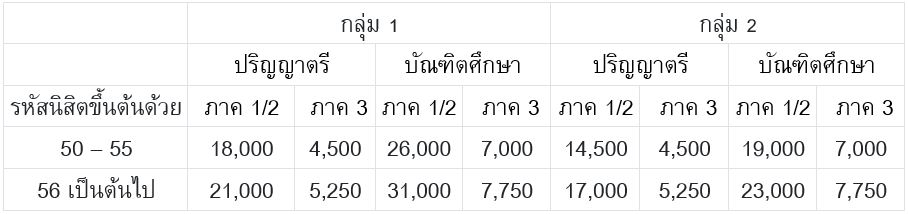

เลขหลักที่ 3 (จากหน้า) ของรหัสนิสิตระดับปริญญาบัณฑิต คือ 3, 4 และบัณฑิตศึกษา คือ 7 <br>
เลข 2 หลักสุดท้ายของรหัสนิสิตเป็นรหัสคณะ <br>
รหัสคณะในกลุ่ม 1 คือ 21 23 25 28 <br>
รหัสคณะในกลุ่ม 2 คือ 22 24 26 27 <br>
และแสดงผลลัพธ์ดังตัวอย่างข้างล่างนี้

### ตัวอย่างการทำงาน: 

Enter student ID : **6033235423**  <br>
Enter semester : **1**  <br>
Registration fee : 21000

### ตัวอย่างการทำงาน: 
Enter student ID : **6070013223**  <br>
Enter semester : **2**  <br>
Registration fee : 31000

### ตัวอย่างการทำงาน: 

Enter student ID : **5443200022**  <br>
Enter semester : **3**  <br>
Registration fee : 4500

### ตัวอย่างการทำงาน: 

Enter student ID : **5443200022**  <br>
Enter semester : **0**  <br>
Invalid semester

### ตัวอย่างการทำงาน: 

Enter student ID : **60499**  <br>
Invalid ID

### ตัวอย่างการทำงาน: 

Enter student ID : **9913235499**  <br> 
Invalid ID

In [ ]:
def run():
    # Registration fee dataset.
    regis_data = {
        1: {
            "old": {"under": [18000, 18000, 4500], "grad": [26000, 26000, 7000]},
            "new": {"under": [21000, 21000, 5250], "grad": [31000, 31000, 7750]}
        },
        2: {
            "old": {"under": [14500, 14500, 4500], "grad": [19000, 19000, 7000]},
            "new": {"under": [17000, 17000, 5250], "grad": [23000, 23000, 7750]}
        }
    }

    student_id = input("Enter student ID: ")

    # Invalid ID if length is less than 10.
    if (len(student_id) != 10):
        return print("Invalid ID")
    else:
        adm_year = int(student_id[0:2])
        stu_type = int(student_id[2])
        faculty = int(student_id[8:10])

        # Check if ID is valid or not.
        if (
            (adm_year >= 50 and adm_year <= 66) and
            stu_type in [3, 4, 7] and
            (faculty >= 21 and faculty <= 28)
        ):
            # Catergorize Faculty Groups
            if (faculty in [21, 23, 25, 28]): faculty_group = 1
            else: faculty_group = 2

            # Catergorize Fee Version
            if (adm_year in [50, 51, 52, 53, 54, 55]): fee_version = "old"
            else: fee_version = "new"

            # Catergorize Degree Level
            if (stu_type == 7): degree = "grad"
            else:  degree = "under"
            
            semester = int(input("Enter semester: ")) - 1 # index starts at 0.
            
            if (semester in [0, 1, 2]):
                regis_fee = regis_data[faculty_group][fee_version][degree][semester]
                return print(f"Registration fee : {regis_fee}")
            else:
                return print("Invalid semester")    
        else:
            return print("Invalid ID")

In [ ]:
'''ตรวจสอบผลลัพธ์ของโปรแกรมด้วยการรันที่ cell นี้'''

run()

In [2]:
'''ตรวจสอบผลการคำนวณ'''

from unittest.mock import patch
from io import StringIO


def test(inputs, expected_output):
    with patch('builtins.input', side_effect=inputs), patch('sys.stdout', new_callable=StringIO) as mock_stdout:
        run()
        assert mock_stdout.getvalue() == expected_output, mock_stdout.getvalue()


In [3]:
'''ตรวจสอบผลการคำนวณและการแสดงผลลัพธ์ให้เหมือนกับโจทย์ที่กำหนดให้'''

'''ปริญญาตรี กลุ่ม 1'''
test(['5233235425', '2'], 'Registration fee : 18000\n')
test(['5443200021', '3'], 'Registration fee : 4500\n')  #
test(['6033235423', '1'], 'Registration fee : 21000\n')  #
test(['6033235423', '3'], 'Registration fee : 5250\n')
print('ok')

ok


In [4]:
'''ตรวจสอบผลการคำนวณและการแสดงผลลัพธ์ให้เหมือนกับโจทย์ที่กำหนดให้'''

'''บัณฑิต กลุ่ม 1'''
test(['5273235421', '2'], 'Registration fee : 26000\n')  # grad
test(['5273235423', '3'], 'Registration fee : 7000\n')  # grad
test(['6070013223', '1'], 'Registration fee : 31000\n')  # grad
test(['6070013228', '3'], 'Registration fee : 7750\n')  # grad
print('ok')

ok


In [5]:
'''ตรวจสอบผลการคำนวณและการแสดงผลลัพธ์ให้เหมือนกับโจทย์ที่กำหนดให้'''

'''ปริญญาตรี กลุ่ม 2'''
test(['5333200024', '1'], 'Registration fee : 14500\n')
test(['5443200022', '3'], 'Registration fee : 4500\n')
test(['6433235426', '2'], 'Registration fee : 17000\n')  #
test(['6533235427', '3'], 'Registration fee : 5250\n')
print('ok')

ok


In [6]:
'''ตรวจสอบผลการคำนวณและการแสดงผลลัพธ์ให้เหมือนกับโจทย์ที่กำหนดให้'''

'''บัณฑิต กลุ่ม 2'''
test(['5173235422', '1'], 'Registration fee : 19000\n')  # grad
test(['5373235424', '3'], 'Registration fee : 7000\n')  # grad
test(['6370013226', '2'], 'Registration fee : 23000\n')  # grad
test(['6570013227', '3'], 'Registration fee : 7750\n')  # grad
print('ok')

ok


In [7]:
'''ตรวจสอบผลการคำนวณและการแสดงผลลัพธ์ให้เหมือนกับโจทย์ที่กำหนดให้'''

'''case Invalid / Invalid semester'''
test(['5443200022', '0'], 'Invalid semester\n')  #
test(['604923'], 'Invalid ID\n')  #
test(['9913235499'], 'Invalid ID\n')  #
print('ok')

ok


In [8]:
'''เทสลับ1'''


'เทสลับ1'

In [9]:
'''เทสลับ2'''


'เทสลับ2'

In [10]:
'''เทสลับ3'''


'เทสลับ3'

In [11]:
'''เทสลับ4'''


'เทสลับ4'

In [12]:
'''เทสลับ5'''


'เทสลับ5'